A UNIFOR quase ninguém deixa em branco

## Que confusões conceituais aparecem nas questões?
**Variável: DS_VT_ESC_OCE**

**Hipótese: Nas questões de menor acerto, os erros do curso se concentram em uma mesma alternativa incorreta, indicando equívoco conceitual comum e não chute.**


In [26]:
from math import erfc, exp, pi, sqrt

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = "../data/2021"
CO_CURSO_UNIFOR_CC = 11730
TP_PRES_PRESENTE = 555
N_QUESTOES_MENOR_ACERTO = 5
CONCENTRACAO_MINIMA = 50  # % dos erros numa mesma alternativa errada; no chute puro seria +-25%

## Dados

In [32]:
# arq3: gabarito, acertos e alternativa marcada no componente específico; arq1: grupo (área) de cada curso
provas = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq3.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "TP_PRES", "DS_VT_GAB_OCE_FIN", "DS_VT_ACE_OCE", "DS_VT_ESC_OCE"],
    dtype={"DS_VT_GAB_OCE_FIN": str, "DS_VT_ACE_OCE": str, "DS_VT_ESC_OCE": str},
)
cursos = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq1.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "CO_GRUPO"],
).drop_duplicates(subset="CO_CURSO")
provas = provas.merge(cursos, on="CO_CURSO", how="left", validate="many_to_one")

# grupo = Ciência da Computação (o mesmo do curso da UNIFOR), só presentes
CO_GRUPO_CC = cursos.loc[cursos["CO_CURSO"] == CO_CURSO_UNIFOR_CC, "CO_GRUPO"].iloc[0]
cc = provas[(provas["CO_GRUPO"] == CO_GRUPO_CC) & (provas["TP_PRES"] == TP_PRES_PRESENTE)]
cc = cc.dropna(subset=["DS_VT_ACE_OCE", "DS_VT_ESC_OCE"]).reset_index(drop=True)
m_unifor = cc["CO_CURSO"] == CO_CURSO_UNIFOR_CC
print(f"CO_GRUPO: {CO_GRUPO_CC} | total de estudantes - Brasil: {len(cc)} | UNIFOR: {m_unifor.sum()}")

CO_GRUPO: 4004 | total de estudantes - Brasil: 9987 | UNIFOR: 36


In [28]:
# Uma coluna por questão. X e Z no gabarito = questões que não contam na nota, então saem da análise.
gabarito = cc["DS_VT_GAB_OCE_FIN"].iloc[0]
questoes = [f"Q{i}" for i in range(1, len(gabarito) + 1)]
validas = [q for q, g in zip(questoes, gabarito) if g not in "XZ"]
resposta_certa = dict(zip(questoes, gabarito))


def separar(coluna):
    tabela = cc[coluna].str.split("", expand=True).iloc[:, 1:-1]
    tabela.columns = questoes
    return tabela[validas]


acertos = separar("DS_VT_ACE_OCE").astype(int)
escolhas = separar("DS_VT_ESC_OCE")  # A-E = alternativa marcada; "." = branco; "*" = rasura
print("questões válidas:", len(validas))

questões válidas: 19


## Resultados

In [29]:
# Questões de menor acerto na UNIFOR
acerto_unifor = (acertos[m_unifor].mean() * 100).round(1)
menor_acerto = acerto_unifor.sort_values().head(6)
menor_acerto

Q18    13.9
Q6     16.7
Q26    19.4
Q1     27.8
Q23    30.6
Q10    30.6
dtype: float64

In [30]:
# Para cada questão: como os erros (alternativas erradas marcadas) se distribuem.
# Se fosse chute, os erros se dividiriam igualmente entre as 4 alternativas erradas (25% cada).
# O teste qui-quadrado (3 graus de liberdade) mede se a distribuição foge disso; p < 0,05 = não parece chute.


def p_valor_qui2_gl3(x):
    return erfc(sqrt(x / 2)) + sqrt(2 * x / pi) * exp(-x / 2)


def erros_por_alternativa(respostas, q):
    erradas = [letra for letra in "ABCDE" if letra != resposta_certa[q]]
    return respostas[q].value_counts().reindex(erradas, fill_value=0)


linhas = []
for q in menor_acerto.index:
    erros = erros_por_alternativa(escolhas[m_unifor], q)
    esperado = erros.sum() / 4
    qui2 = ((erros - esperado) ** 2 / esperado).sum()
    erros_brasil = erros_por_alternativa(escolhas, q)
    linhas.append({
        "questao": q,
        "acerto_unifor": menor_acerto[q],
        "gabarito": resposta_certa[q],
        "n_erros": erros.sum(),
        "erro_mais_comum": erros.idxmax(),
        "pct_dos_erros": round(erros.max() / erros.sum() * 100, 1),
        "p_valor": round(p_valor_qui2_gl3(qui2), 4),
        "erro_mais_comum_brasil": erros_brasil.idxmax(),
        "pct_dos_erros_brasil": round(erros_brasil.max() / erros_brasil.sum() * 100, 1),
    })
confusoes = pd.DataFrame(linhas).set_index("questao")
confusoes["concentrado"] = (confusoes["pct_dos_erros"] >= CONCENTRACAO_MINIMA) & (confusoes["p_valor"] < 0.05)
confusoes

,acerto_unifor,gabarito,n_erros,erro_mais_comum,pct_dos_erros,p_valor,erro_mais_comum_brasil,pct_dos_erros_brasil,concentrado
questao,,,,,,,,,
Q18,13.9,A,31,E,45.2,0.0495,E,49.2,False
Q6,16.7,C,30,A,50.0,0.0018,A,56.4,True
Q26,19.4,C,29,E,37.9,0.1668,D,33.5,False
Q1,27.8,E,26,D,65.4,0.0000,D,36.9,True
Q23,30.6,E,25,C,36.0,0.3031,C,33.6,False
Q10,30.6,E,24,D,45.8,0.0620,D,38.0,False


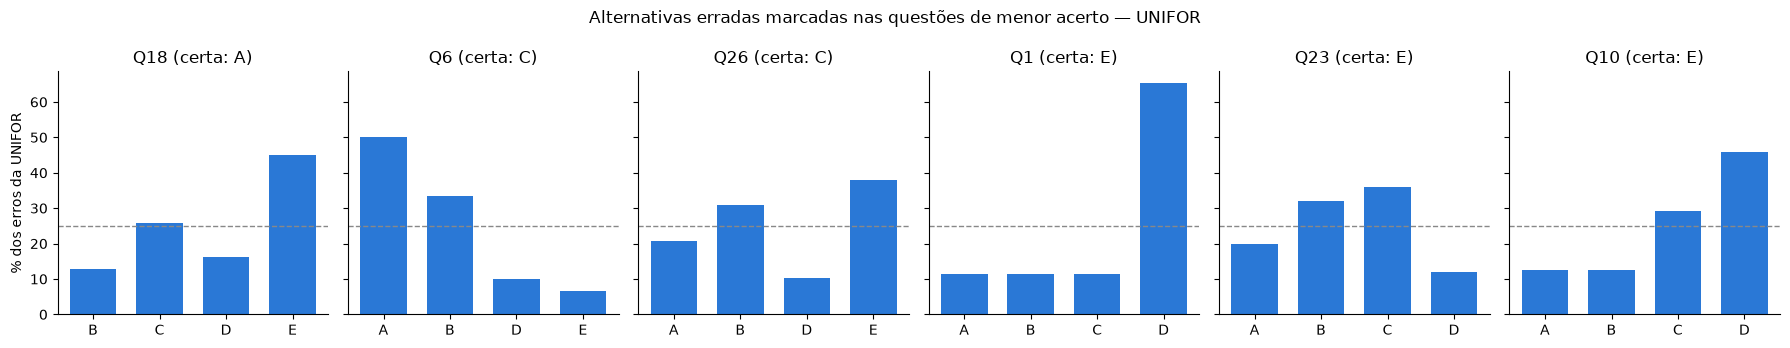

In [31]:
# Distribuição dos erros da UNIFOR em cada questão; a linha tracejada é o esperado no chute (25%)
fig, axes = plt.subplots(1, len(confusoes), figsize=(3 * len(confusoes), 3.5), sharey=True)
for ax, q in zip(axes, confusoes.index):
    erros = erros_por_alternativa(escolhas[m_unifor], q)
    pct = erros / erros.sum() * 100
    ax.bar(pct.index, pct.values, color="#2a78d6", width=0.7)
    ax.axhline(25, color="#888888", linestyle="--", linewidth=1)
    ax.set_title(f"{q} (certa: {resposta_certa[q]})")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("% dos erros da UNIFOR")
fig.suptitle("Alternativas erradas marcadas nas questões de menor acerto — UNIFOR")
plt.tight_layout()
plt.show()

## Conclusão

A hipótese se confirma em parte. Das 6 questões de menor acerto da UNIFOR, 2 têm os erros concentrados numa mesma alternativa errada (50% ou mais dos erros e p < 0,05), o que indica um equívoco comum e não chute:

- Q1 (certa: E): 65,4% dos erros foram na D (17 de 26). No Brasil, a D também é o erro mais comum, mas com só 36,9%. Ou seja, essa confusão é mais forte na UNIFOR do que no resto do país.
- Q6 (certa: C): 50,0% dos erros foram na A. No Brasil acontece o mesmo (56,4% na A), então é uma confusão comum a todos os cursos, não específica da UNIFOR.

A Q18 fica no limite: 45,2% dos erros na E (p = 0,0495), o mesmo padrão do Brasil (49,2% na E). Na Q26, na Q23 e na Q10, os erros estão mais espalhados entre as alternativas, então não dá para descartar chute. Na Q23, por exemplo, a alternativa errada mais marcada (C) ficou com só 36,0% dos erros (p = 0,303).

Para entender qual é o equívoco, é preciso ler na prova de 2021 o enunciado da Q1, da Q6 e da Q18 e a alternativa errada mais marcada em cada uma.

Com 36 alunos, cada questão tem só entre 24 e 31 erros, então esses percentuais variam bastante. Q23 e Q10 empatam em 30,6% de acerto, por isso as duas entraram na lista.

----------------------

link pra prova (Ciência da computação (bacharelado)) -> 
https://www.gov.br/inep/pt-br/areas-de-atuacao/avaliacao-e-exames-educacionais/enade/provas-e-gabaritos/2021 

**Questão 9 (Q1)**, Sistemas Operacionais: escalonamento

- Certa: E, escalonamento por prioridades em sistemas interativos.
- Mais marcada pelos que erraram: D, round-robin em sistemas de tempo real, com 65% dos erros na UNIFOR contra 37% no Brasil.
- Possível confusão: o round-robin divide o tempo da CPU em fatias iguais entre os processos e costuma ser associado a sistemas interativos, enquanto sistemas de tempo real tendem a usar algoritmos voltados a prazos, como o RMS. Uma hipótese é que os alunos tenham associado "rodízio" a "tempo real".
- Parece ser a confusão mais forte e mais própria da UNIFOR. Também é a questão que mais se afastou do Brasil no q5 (13 pontos abaixo).


**Questão 14 (Q6)**, Arquitetura de Computadores: Von Neumann

- Certa: C. A asserção I é verdadeira e a II é falsa.
- Mais marcada pelos que erraram: A, as duas verdadeiras e a II justificando a I, com 50% dos erros na UNIFOR e 56% no Brasil.
- Possível confusão: a asserção II parece descrever a busca antecipada de instruções (prefetch, pipeline), que seria uma otimização posterior e não uma característica da arquitetura de Von Neumann, cuja ideia central é guardar dados e instruções na mesma memória. Talvez os alunos tenham aceitado uma descrição técnica que soa correta como se fosse a definição.
- Pelos números, parece ser uma confusão de todo o país, e não específica da UNIFOR.


**Questão 26 (Q18)**, Interação Humano-Computador: interfaces adaptativas

- Certa: A, só a I.
- Mais marcada pelos que erraram: E, I, II e III, com 45% dos erros na UNIFOR e 49% no Brasil.
- Possível confusão: as afirmações II e III parecem trocar os níveis de lugar, já que layouts e guias de estilo seriam técnicas de apresentação, e anotação, ocultação e ordenação de links seriam técnicas de navegação. É provável que quem marcou E não tenha percebido essa troca e aceitado todas as afirmações.
- É a questão com menos acerto da UNIFOR (13,9%), e o padrão de erro parece igual ao do Brasil.